# Ensembles and uncertainty bands

**Atlas source reading copy · browser-network**

[Course guide](index.ipynb) · [Pinned original](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/0e32b2477ba5c0030985e25f1071d94cddabf130/content/12-ensembles.ipynb)



Browser-only piplite prepares numpy, matplotlib, pandas, xarray and ipywidgets. Calculations use earthlab.py and original synthetic arrays, not observations or real Digital Twin outputs. Optional widget controls need the source frontend; static figures and numerical results provide alternatives. Real DestinE accounts, Polytope/Data Lake services, GRIB/netCDF decoding and HPC remain explicit source/native continuations. No credentials or service requests are required for these defaults.

**Provenance:** `content/12-ensembles.ipynb` at `0e32b2477ba5c0030985e25f1071d94cddabf130`; original SHA-256 `74d96afee6cf42a7dfdd9f44aa9c43e1fbeb6618dfda8b7238a915cbe2e07718`. Original code MIT; original prose, generated numerical data and cleared artwork CC BY 4.0, with attribution and Atlas adaptation notice. Official DestinE references/datasets are linked context, not copied inputs.

**Verification:** imported by static inspection; saved upstream outputs cleared. Runtime compatibility is separate from executed verification. See the course guide for dependencies, excluded assets, aliases and original credits.


![Original abstract globe and synthetic weather streamlines](assets/splash.png)

# Ensembles and uncertainty bands

**Lesson 12 · Original synthetic data · Independent educational project**

## Objectives

Summarize member spread; distinguish uncertainty types.

[Previous](11-interpolation.ipynb) · [Notebook source](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/content/12-ensembles.ipynb) · [Next](13-verification.ipynb)

[Open this notebook in JupyterLite](https://jltobias.github.io/JupyterLite-Destination-Earth-Digital-Twin/lab/index.html?path=12-ensembles.ipynb) — public deployment pending until verified. For a local build, open the matching filename from the Lab file browser.

Run every code cell in order. The first run in JupyterLite downloads browser packages; it needs an internet connection. No account or credentials are used. The interactive visual lessons use ipywidgets, and the gallery provides additional live controls.

## Prepare the browser-sized environment

The shared `earthlab.py` helper lives beside every notebook. The same source notebook is used by the book and Lab.

In [1]:
import sys
if sys.platform == "emscripten":
    import piplite
    await piplite.install(["numpy", "matplotlib", "pandas", "xarray", "ipywidgets"])
import numpy as np
import matplotlib.pyplot as plt
import earthlab as lab
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print(lab.PROVENANCE)

Original synthetic teaching data; not observations or DestinE model output


## Worked experiment

Run this original experiment and inspect both its figure and numerical checks.

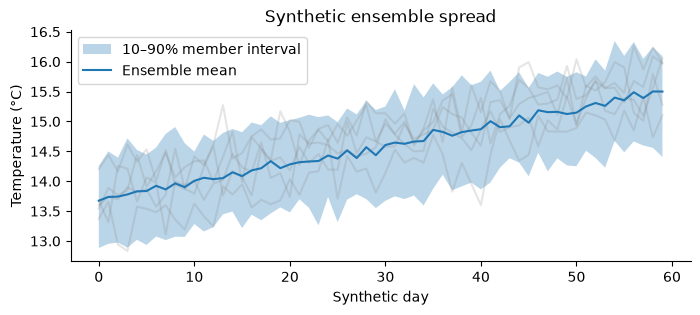

Average interval width: 1.5642402864464693 °C


In [2]:
members = lab.ensemble()
mean = members.mean(axis=0)
low, high = np.quantile(members, [.1, .9], axis=0)
assert np.all(low <= high)
assert members.shape == (30, 60)
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(members[:5].T, color="gray", alpha=.2)
ax.fill_between(np.arange(60), low, high, alpha=.3, label="10–90% member interval")
ax.plot(mean, label="Ensemble mean")
ax.set(xlabel="Synthetic day", ylabel="Temperature (°C)", title="Synthetic ensemble spread")
ax.legend(); plt.show()
print("Average interval width:", (high-low).mean(), "°C")

## Exercise

Generate ensembles with 10 and 100 members. Compare the stability of estimated quantiles using several random seeds.

Add a code cell with your modification and at least one assertion that would catch an incorrect result. Keep the original experiment as a reference.

## Interpretation and limits

This interval summarizes generated members; it is not a calibrated probability statement about future observations. Structural model and scenario uncertainty are absent.

**Check your reasoning:** identify one result the code establishes and one conclusion the demonstration cannot establish.

## References and provenance

- [Conceptual or software reference](https://destine.ecmwf.int/climate-digital-twin/) — linked for background; no text, external notebook code or data were copied.
- [Destination Earth initiative source index](https://github.com/destination-earth/DestinE).
- Generated arrays and equations: original project teaching material, CC BY 4.0; helper code: MIT. No authentic DestinE outputs or observational datasets are used.
- The abstract splash was generated for this project. See the repository's [attribution record](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/ATTRIBUTIONS.md).